# Sfida 1: il problema del dataset *banknote authentication*

Faremo un'analisi quasi realistica del dataset *banknote authentication*. Si può scaricare da questo [link](https://archive.ics.uci.edu/dataset/267/banknote+authentication) oppure dalla [repo GitHub](https://github.com/LorenzoTonet/Intro_to_ML_26-27/blob/main/data/data_banknote_authentication.txt).

## Descrizione del dataset

I dati sono stati estratti da immagini di esemplari di banconote, sia autentiche sia contraffatte. Le immagini sono state acquisite con una telecamera industriale, di quelle usate di solito per il controllo di stampa. Le immagini finali sono di 400×400 pixel. Per via dell'obiettivo e della distanza dall'oggetto, si sono ottenute immagini in scala di grigi con una risoluzione di circa 660 dpi. Le feature sono state estratte dalle immagini con la trasformata wavelet.
Le feature sono:
1. varianza dell'immagine trasformata con wavelet (continua)
2. asimmetria (*skewness*) dell'immagine trasformata con wavelet (continua)
3. curtosi dell'immagine trasformata con wavelet (continua)
4. entropia dell'immagine (continua)
5. classe (intero)

## Descrizione del compito
È un problema di classificazione binaria. Il lavoro si divide in quattro parti:

1. Caricamento dei dati e pre-trattamento.
2. Esplorazione dei dati con tecniche di apprendimento non supervisionato.
3. Costruzione di diversi modelli di apprendimento supervisionato.
4. Valutazione dei risultati.

#### Librerie

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

<div style="background-color:rgba(26,115,232,0.15); border-left:6px solid #1a73e8; padding:12px; border-radius:4px">

### 1. Pre-trattamento dei dati

Carica i dati e osservali. Serve qualche tipo di scaling? Perché? I dati sono ordinati nel dataset originale? Questo può creare problemi? Come si risolve?

</div>

#### 1.1 Carico e osservo i dati

In [2]:
# 1. Definisco i nomi delle colonne
colonne = ["varianza", "asimmetria", "curtosi", "entropia", "classe"]

# 2. Carico il dataset
df = pd.read_csv("data_banknote_authentication.txt", header=None, names=colonne)

# 3. Controllo le dimensioni e guardo le prime righe
print("Dimensioni:", df.shape)
display(df.head())

# 4. Controllo se ci sono valori mancanti
print("Valori mancanti:\n", df.isna().sum())

# 5. Conto le righe duplicate
print("\nRighe duplicate:", df.duplicated().sum())

# 6. Guardo quante banconote ci sono per classe
print("\nDistribuzione delle classi:\n", df["classe"].value_counts())

# 7. Rimuovo i duplicati
df = df.drop_duplicates().reset_index(drop=True)
print("\nDimensioni dopo la rimozione:", df.shape)

Dimensioni: (1372, 5)


,varianza,asimmetria,curtosi,entropia,classe
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Valori mancanti:
 varianza      0
asimmetria    0
curtosi       0
entropia      0
classe        0
dtype: int64

Righe duplicate: 24

Distribuzione delle classi:
 classe
0    762
1    610
Name: count, dtype: int64

Dimensioni dopo la rimozione: (1348, 5)


**Osservazioni sui dati**

Il dataset ha 1372 banconote e nessun valore mancante. Ho tolto 24 righe duplicate (tutte di classe 0) per evitare che una copia finisca nel training e l'altra nel test. Restano 1348 righe: 738 di classe 0 e 610 di classe 1, quindi le classi sono abbastanza bilanciate.

#### 1.2 Serve lo scaling?

                mean       std      min      max
varianza    0.445785  2.862906  -7.0421   6.8248
asimmetria  1.909039  5.868600 -13.7731  12.9516
curtosi     1.413578  4.328365  -5.2861  17.9274
entropia   -1.168712  2.085877  -8.5482   2.4495


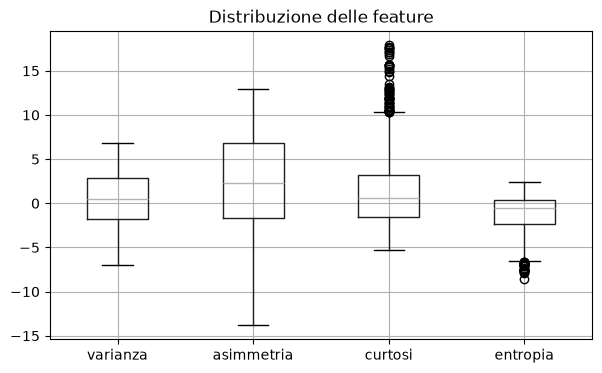

In [3]:
# 1. Separo le feature dalla classe
X = df.drop(columns="classe")
y = df["classe"]

# 2. Confronto media, deviazione standard e intervallo delle feature
print(X.describe().T[["mean", "std", "min", "max"]])

# 3. Visualizzo le distribuzioni con un boxplot
X.boxplot(figsize=(7, 4))
plt.title("Distribuzione delle feature")
plt.show()

**Serve qualche tipo di scaling? Perché?**

Sì. Le feature hanno scale diverse: la deviazione standard dell'asimmetria (5.87) è quasi tre volte quella dell'entropia (2.09), e anche gli intervalli sono molto diversi. Dal boxplot noto anche degli outlier, soprattutto nella curtosi e nell'entropia.

Molti dei metodi che userò (PCA, k-means, DBSCAN, t-SNE, k-NN e la regressione logistica regolarizzata) dipendono dalle distanze o dalla varianza: senza scaling le feature con valori più grandi conterebbero di più. Per questo uso uno `StandardScaler`, che porta ogni feature a media 0 e deviazione standard 1. Naive Bayes e l'albero di decisione invece non ne hanno bisogno.

#### 1.3 I dati sono ordinati?

Prima riga di classe 1: 738


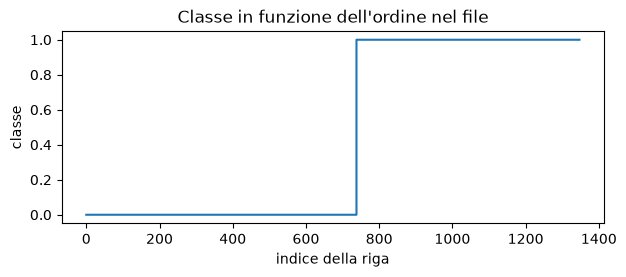

In [4]:
# 1. Controllo dove inizia la classe 1
print("Prima riga di classe 1:", y.idxmax())

# 2. Visualizzo la classe in funzione della posizione nel file
plt.figure(figsize=(7, 2.5))
plt.plot(y.values, drawstyle="steps-post")
plt.xlabel("indice della riga")
plt.ylabel("classe")
plt.title("Classe in funzione dell'ordine nel file")
plt.show()

**I dati sono ordinati nel dataset originale?**

Sì. Dal grafico vedo che la classe cambia una sola volta: le prime 738 righe sono di classe 0 e le ultime 610 di classe 1.

**Può creare problemi?**

Sì. Se prendessi per esempio le ultime 372 righe come test set, avrei solo banconote di classe 1, e i risultati non avrebbero senso. Lo stesso succederebbe con la cross-validation se i fold fossero presi in ordine.

**Come si può risolvere?**

Rimescolo le righe in modo casuale prima di dividere i dati, fissando un seed per avere risultati riproducibili. Nel punto 3 uso inoltre la divisione stratificata, così ogni sottoinsieme mantiene la stessa proporzione tra le classi.

#### 1.4 Rimescolo e standardizzo

In [5]:
# 1. Rimescolo le righe in modo casuale
df_mescolato = df.sample(frac=1, random_state=42).reset_index(drop=True)
X = df_mescolato.drop(columns="classe").values
y = df_mescolato["classe"].values
print("Prime 20 classi dopo il rimescolamento:", y[:20])

# 2. Standardizzo le feature
X_scalato = StandardScaler().fit_transform(X)
print("Media dopo lo scaling:", X_scalato.mean(axis=0).round(3))
print("Dev. std dopo lo scaling:", X_scalato.std(axis=0).round(3))

Prime 20 classi dopo il rimescolamento: [0 1 1 1 1 1 1 1 1 0 0 0 1 0 0 0 0 0 0 1]
Media dopo lo scaling: [0. 0. 0. 0.]
Dev. std dopo lo scaling: [1. 1. 1. 1.]


**Risultato**

Dopo il rimescolamento le classi sono mescolate e dopo lo scaling tutte le feature hanno media 0 e deviazione standard 1. Qui adatto lo scaler su tutto il dataset perché nel punto 2 esploro solo i dati; nel punto 3 lo adatterò solo sul training set, per evitare il *data leakage*.

<div style="background-color:rgba(26,115,232,0.15); border-left:6px solid #1a73e8; padding:12px; border-radius:4px">

### 2. Apprendimento non supervisionato

Applica la PCA e rappresenta le prime due componenti, colorando i punti in base alla classe. In questa proiezione le classi sono linearmente separabili? Cosa succede se applico k-means con due cluster in questo spazio? E se uso tutte le coordinate? Prova anche t-SNE per la proiezione e DBSCAN per il clustering, e commenta i risultati.

</div>

#### 2.1 PCA sulle prime due componenti

Varianza spiegata: [0.544 0.323 0.088 0.044]
Varianza spiegata dalle prime due: 0.867


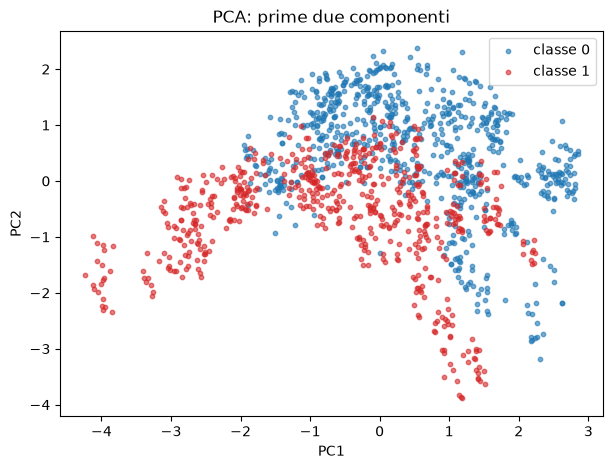

In [6]:
# 1. Applico la PCA ai dati standardizzati
pca = PCA()
X_pca = pca.fit_transform(X_scalato)

# 2. Controllo quanta varianza spiega ogni componente
print("Varianza spiegata:", pca.explained_variance_ratio_.round(3))
print("Varianza spiegata dalle prime due:", pca.explained_variance_ratio_[:2].sum().round(3))

# 3. Rappresento le prime due componenti colorando per classe
plt.figure(figsize=(7, 5))
for classe, colore in zip([0, 1], ["tab:blue", "tab:red"]):
    plt.scatter(X_pca[y == classe, 0], X_pca[y == classe, 1], s=10, alpha=0.6, c=colore, label=f"classe {classe}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: prime due componenti")
plt.legend()
plt.show()

**In questa proiezione le classi sono linearmente separabili?**

No. Le prime due componenti spiegano circa l'87% della varianza, e nel grafico le classi tendono a stare in zone diverse (la classe 1 in basso a sinistra, la classe 0 in alto a destra), ma al centro si sovrappongono molto: non esiste una retta che le separi senza sbagliare molti punti.

Secondo me il motivo è che la PCA non usa le etichette: cerca le direzioni di massima varianza, non quelle che separano meglio le classi.

#### 2.2 K-means sulle prime due componenti

,cluster 0,cluster 1
classe 0,339,399
classe 1,358,252


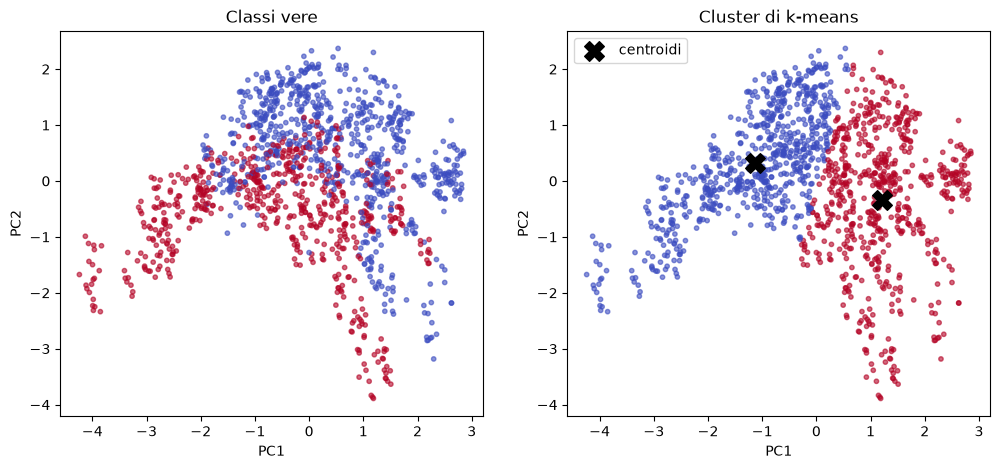

In [7]:
# 1. Applico k-means con 2 cluster sulle prime due componenti
kmeans_2d = KMeans(n_clusters=2, n_init=10, random_state=42)
cluster_2d = kmeans_2d.fit_predict(X_pca[:, :2])

# 2. Confronto i cluster trovati con le classi vere
tabella_2d = pd.crosstab(y, cluster_2d)
tabella_2d.index = ["classe 0", "classe 1"]
tabella_2d.columns = ["cluster 0", "cluster 1"]
display(tabella_2d)

# 3. Confronto graficamente classi vere e cluster
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", s=10, alpha=0.6)
ax[0].set_title("Classi vere")
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_2d, cmap="coolwarm", s=10, alpha=0.6)
ax[1].scatter(*kmeans_2d.cluster_centers_.T, c="black", marker="X", s=200, label="centroidi")
ax[1].set_title("Cluster di k-means")
ax[1].legend()
for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.show()


**Cosa succede applicando k-means con due cluster in questo spazio?**

Il risultato è scarso. K-means divide i punti più o meno con una linea verticale intorno a PC1 = 0, ma questa divisione non corrisponde alle classi: dalla tabella vedo che entrambi i cluster contengono molte banconote di tutte e due le classi.

Secondo me il motivo è che k-means cerca gruppi compatti e sferici attorno a un centroide, mentre qui le classi hanno forme allungate e si sovrappongono al centro. Quindi k-means taglia semplicemente la nuvola di punti in due metà.

#### 2.3 K-means su tutte le coordinate

,cluster 0,cluster 1
classe 0,402,336
classe 1,254,356


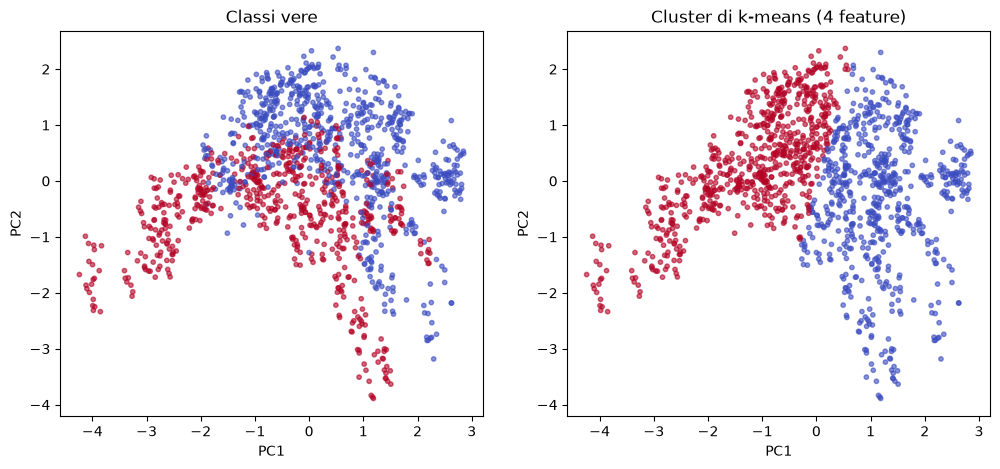

In [8]:
# 1. Applico k-means con 2 cluster su tutte e 4 le feature standardizzate
kmeans_4d = KMeans(n_clusters=2, n_init=10, random_state=42)
cluster_4d = kmeans_4d.fit_predict(X_scalato)

# 2. Confronto i cluster trovati con le classi vere
tabella_4d = pd.crosstab(y, cluster_4d)
tabella_4d.index = ["classe 0", "classe 1"]
tabella_4d.columns = ["cluster 0", "cluster 1"]
display(tabella_4d)

# 3. Visualizzo i cluster sul piano delle prime due componenti
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", s=10, alpha=0.6)
ax[0].set_title("Classi vere")
ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_4d, cmap="coolwarm", s=10, alpha=0.6)
ax[1].set_title("Cluster di k-means (4 feature)")
for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.show()


**E se uso tutte le coordinate?**

Non cambia quasi niente: la tabella mostra di nuovo cluster con molte banconote di entrambe le classi, e dal grafico la divisione è quasi identica a prima, un taglio intorno a PC1 = 0. I colori sono invertiti, ma solo perché k-means numera i cluster a caso.

Secondo me il risultato è simile perché le prime due componenti spiegano già l'87% della varianza, quindi le distanze usate da k-means dipendono soprattutto da quelle. Il problema resta lo stesso: le classi non formano due gruppi compatti.

#### 2.4 Proiezione con t-SNE

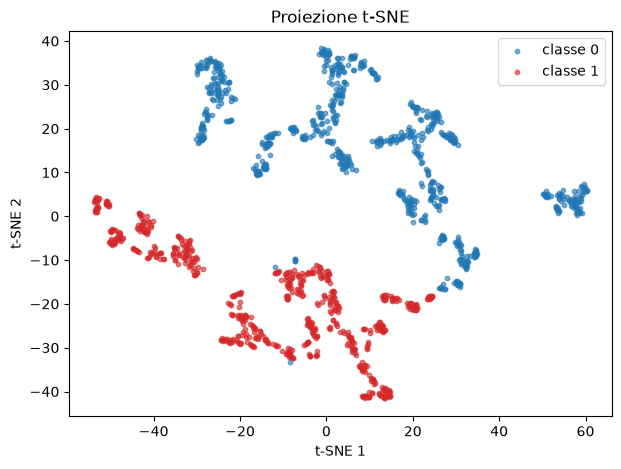

In [9]:
# 1. Proietto i dati standardizzati in 2 dimensioni con t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scalato)

# 2. Rappresento la proiezione colorando per classe
plt.figure(figsize=(7, 5))
for classe, colore in zip([0, 1], ["tab:blue", "tab:red"]):
    plt.scatter(X_tsne[y == classe, 0], X_tsne[y == classe, 1], s=10, alpha=0.6, c=colore, label=f"classe {classe}")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Proiezione t-SNE")
plt.legend()
plt.show()


**Commento sulla proiezione t-SNE**

Con t-SNE le due classi risultano quasi completamente separate: la classe 0 sta in alto a destra, la classe 1 in basso a sinistra, e ogni classe è divisa in tanti piccoli gruppi allungati.

Anche t-SNE non usa le etichette, quindi questo vuol dire che le banconote vicine tra loro nello spazio a 4 dimensioni appartengono quasi sempre alla stessa classe. La PCA non riusciva a mostrarlo perché è lineare e cerca solo le direzioni di massima varianza, mentre t-SNE conserva chi è vicino a chi. Questo mi fa pensare che k-NN funzionerà bene nel punto 3.

#### 2.5 Clustering con DBSCAN

Numero di cluster: 13
Punti di rumore: 42


,classe 0,classe 1
cluster,,
-1,28,14
0,5,486
1,0,36
2,658,0
3,24,0
4,11,0
5,0,9
6,0,10
7,0,10


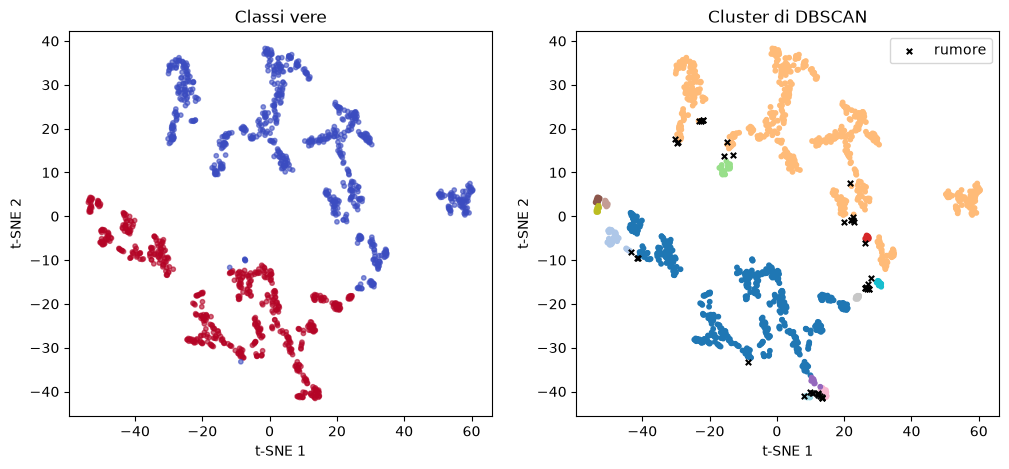

In [10]:
# 1. Applico DBSCAN alle feature standardizzate
cluster_db = DBSCAN(eps=0.45, min_samples=8).fit_predict(X_scalato)
rumore = cluster_db == -1
print("Numero di cluster:", len(set(cluster_db[~rumore])))
print("Punti di rumore:", rumore.sum())

# 2. Confronto i cluster trovati con le classi vere
tabella_db = pd.crosstab(cluster_db, y)
tabella_db.index.name = "cluster"
tabella_db.columns = ["classe 0", "classe 1"]
display(tabella_db)

# 3. Visualizzo i cluster sul piano t-SNE
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="coolwarm", s=10, alpha=0.6)
ax[0].set_title("Classi vere")
ax[1].scatter(X_tsne[~rumore, 0], X_tsne[~rumore, 1], c=cluster_db[~rumore], cmap="tab20", s=10)
ax[1].scatter(X_tsne[rumore, 0], X_tsne[rumore, 1], c="black", marker="x", s=15, label="rumore")
ax[1].set_title("Cluster di DBSCAN")
ax[1].legend()
for a in ax:
    a.set_xlabel("t-SNE 1")
    a.set_ylabel("t-SNE 2")
plt.show()

**Commento sul clustering con DBSCAN**

Ho provato alcuni valori di `eps` e ho scelto 0.45: con valori più piccoli DBSCAN trova tantissimi cluster piccoli e considera rumore molti punti, mentre con valori più grandi i cluster delle due classi si fondono.

Con `eps = 0.45` il risultato è molto migliore di k-means. DBSCAN trova due grandi cluster che corrispondono quasi esattamente alle due classi (658 banconote di classe 0 e 486 di classe 1, con solo 5 errori), più alcuni gruppetti piccoli, quasi tutti di una sola classe, e 42 punti di rumore.

Secondo me funziona perché DBSCAN non cerca gruppi sferici ma segue le zone dense dei dati, qualunque forma abbiano. Il risultato però dipende molto da `eps`.

In generale, dal punto 2 capisco che le classi non sono separabili nella proiezione PCA e non formano due gruppi compatti, quindi k-means non le trova; però le banconote vicine tra loro appartengono quasi sempre alla stessa classe, come mostrano t-SNE e DBSCAN.

<div style="background-color:rgba(26,115,232,0.15); border-left:6px solid #1a73e8; padding:12px; border-radius:4px">

### 3. Apprendimento supervisionato

Separa un sottoinsieme di 372 elementi da tenere come test set. Con il resto dei dati costruisci questi modelli: regressione logistica, albero di decisione (con l'algoritmo ID3), Naive Bayes e k-NN.

Studia l'effetto della regolarizzazione dove è possibile, e usa la cross-validation per scegliere gli iperparametri quando serve.

Confronta le prestazioni sul test set in termini di accuratezza, precisione, recall e F1-score. Commenta questi risultati alla luce di quelli ottenuti con l'analisi non supervisionata. Sapresti proporre un modo per migliorarli?

</div>

#### 3.1 Divisione in training e test set

In [11]:
# 1. Separo 372 elementi per il test set, mantenendo la proporzione delle classi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=372, stratify=y, random_state=42)

# 2. Controllo le dimensioni e la distribuzione delle classi
print("Training set:", X_train.shape, "| classe 0:", (y_train == 0).sum(), "| classe 1:", (y_train == 1).sum())
print("Test set:    ", X_test.shape, "| classe 0:", (y_test == 0).sum(), "| classe 1:", (y_test == 1).sum())

# 3. Adatto lo scaler solo sul training set e lo applico a entrambi
scaler = StandardScaler()
X_train_scalato = scaler.fit_transform(X_train)
X_test_scalato = scaler.transform(X_test)

Training set: (976, 4) | classe 0: 534 | classe 1: 442
Test set:     (372, 4) | classe 0: 204 | classe 1: 168


**Risultato**

Ho diviso i dati in 976 elementi di training e 372 di test, usando la stratificazione: in entrambi la classe 1 è circa il 45%, come nel dataset completo. Lo scaler è adattato solo sul training set e poi applicato al test set, così il test set resta completamente "nuovo" per i modelli.

#### 3.2 Regressione logistica

Miglior C: 3.162
Accuratezza media in CV: 0.9939


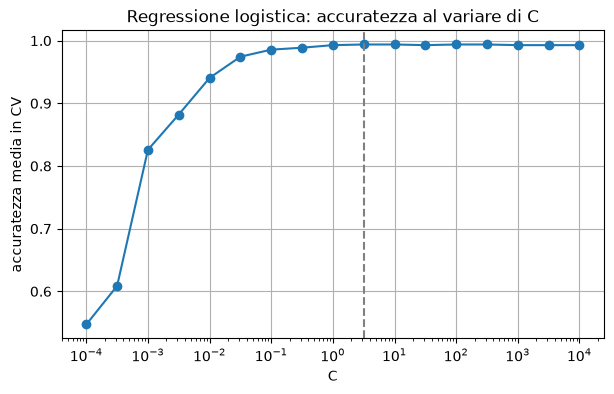

In [12]:
# 1. Definisco la cross-validation stratificata a 5 fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Provo diversi valori di C con la cross-validation
valori_C = np.logspace(-4, 4, 17)
griglia_log = GridSearchCV(LogisticRegression(max_iter=1000), {"C": valori_C}, cv=cv, scoring="accuracy")
griglia_log.fit(X_train_scalato, y_train)
modello_log = griglia_log.best_estimator_
print("Miglior C:", round(griglia_log.best_params_["C"], 3))
print("Accuratezza media in CV:", round(griglia_log.best_score_, 4))

# 3. Visualizzo l'effetto della regolarizzazione
plt.figure(figsize=(7, 4))
plt.semilogx(valori_C, griglia_log.cv_results_["mean_test_score"], marker="o")
plt.axvline(griglia_log.best_params_["C"], color="gray", linestyle="--")
plt.xlabel("C")
plt.ylabel("accuratezza media in CV")
plt.title("Regressione logistica: accuratezza al variare di C")
plt.grid(True)
plt.show()

**Effetto della regolarizzazione**

Nella regressione logistica la regolarizzazione è controllata da C: più C è piccolo, più la regolarizzazione è forte. Con C molto piccolo (0.0001) i coefficienti sono schiacciati quasi a zero e l'accuratezza è circa 55%, perché il modello predice sempre la classe più frequente. Aumentando C l'accuratezza sale rapidamente e da C ≈ 1 in poi resta stabile intorno al 99.3%. La cross-validation sceglie C ≈ 3.16, con un'accuratezza del 99.4%.

È interessante che un modello lineare funzioni così bene, visto che nella proiezione PCA le classi non erano linearmente separabili: la separazione esiste nello spazio a 4 dimensioni, ma non si vede nelle prime due componenti.

#### 3.3 Albero di decisione (ID3)

In [13]:
# Implemento ID3 partendo dalla versione del Lab-05, adattata ad array numpy
class ID3:
    """Albero ID3 per feature discrete: un ramo per ogni valore della feature."""

    def entropia(self, y):
        # 1. Calcolo la proporzione di ogni classe
        p = np.bincount(y) / len(y)
        p = p[p > 0]

        # 2. Sommo -p * log2(p) su tutte le classi
        return -np.sum(p * np.log2(p))

    def guadagno(self, X, y, j):
        # 1. Calcolo l'entropia media pesata dei sottoinsiemi creati dalla feature j
        entropia_pesata = 0
        for valore in np.unique(X[:, j]):
            mask = X[:, j] == valore
            entropia_pesata += mask.mean() * self.entropia(y[mask])

        # 2. Il guadagno è quanto si riduce l'entropia
        return self.entropia(y) - entropia_pesata

    def costruisci(self, X, y, feature_disponibili):
        classe_frequente = np.bincount(y).argmax()

        # 1. Mi fermo se il nodo è puro o se non ho più feature: creo una foglia
        if len(np.unique(y)) == 1 or len(feature_disponibili) == 0:
            return classe_frequente

        # 2. Scelgo la feature con il guadagno informativo massimo
        j = max(feature_disponibili, key=lambda f: self.guadagno(X, y, f))

        # 3. Creo un ramo per ogni valore della feature e costruisco i sottoalberi
        rami = {}
        for valore in np.unique(X[:, j]):
            mask = X[:, j] == valore
            rami[valore] = self.costruisci(X[mask], y[mask], [f for f in feature_disponibili if f != j])
        return {"feature": j, "rami": rami, "default": classe_frequente}

    def fit(self, X, y):
        self.albero = self.costruisci(X, y, list(range(X.shape[1])))
        return self

    def predici_uno(self, x, nodo):
        # 1. Scendo l'albero finché non arrivo a una foglia
        while isinstance(nodo, dict):
            # 2. Se il valore non è mai stato visto, uso la classe più frequente del nodo
            nodo = nodo["rami"].get(x[nodo["feature"]], nodo["default"])
        return nodo

    def predict(self, X):
        return np.array([self.predici_uno(x, self.albero) for x in X])

    def score(self, X, y):
        return np.mean(self.predict(X) == y)

Miglior numero di bin: 8
Accuratezza media in CV: 0.9836


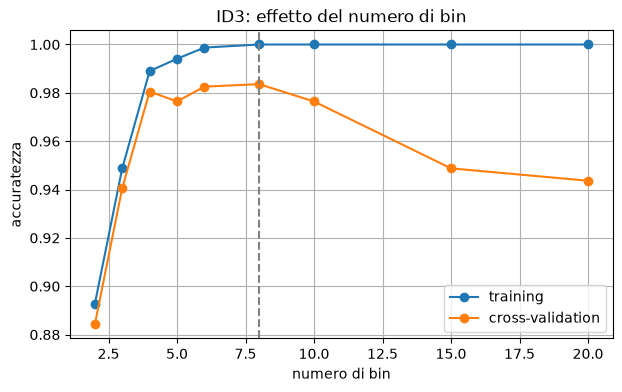

In [14]:
# 1. Definisco una funzione che divide ogni feature in n_bin intervalli
def discretizza(X_fit, X_applica, n_bin):
    X_fit_d = np.zeros_like(X_fit, dtype=int)
    X_applica_d = np.zeros_like(X_applica, dtype=int)
    for j in range(X_fit.shape[1]):
        # Calcolo i bordi dei bin con i quantili, solo sui dati di fit
        bordi = np.quantile(X_fit[:, j], np.linspace(0, 1, n_bin + 1))[1:-1]
        # Assegno a ogni valore l'indice del suo bin
        X_fit_d[:, j] = np.digitize(X_fit[:, j], bordi)
        X_applica_d[:, j] = np.digitize(X_applica[:, j], bordi)
    return X_fit_d, X_applica_d

# 2. Provo diversi numeri di bin con la cross-validation
valori_bin = [2, 3, 4, 5, 6, 8, 10, 15, 20]
acc_train, acc_cv = [], []
for n_bin in valori_bin:
    acc_train_fold, acc_cv_fold = [], []
    for idx_train, idx_val in cv.split(X_train, y_train):
        X_tr_d, X_val_d = discretizza(X_train[idx_train], X_train[idx_val], n_bin)
        albero = ID3().fit(X_tr_d, y_train[idx_train])
        acc_train_fold.append(albero.score(X_tr_d, y_train[idx_train]))
        acc_cv_fold.append(albero.score(X_val_d, y_train[idx_val]))
    acc_train.append(np.mean(acc_train_fold))
    acc_cv.append(np.mean(acc_cv_fold))

miglior_bin = valori_bin[np.argmax(acc_cv)]
print("Miglior numero di bin:", miglior_bin)
print("Accuratezza media in CV:", round(max(acc_cv), 4))

# 3. Visualizzo l'effetto del numero di bin
plt.figure(figsize=(7, 4))
plt.plot(valori_bin, acc_train, marker="o", label="training")
plt.plot(valori_bin, acc_cv, marker="o", label="cross-validation")
plt.axvline(miglior_bin, color="gray", linestyle="--")
plt.xlabel("numero di bin")
plt.ylabel("accuratezza")
plt.title("ID3: effetto del numero di bin")
plt.legend()
plt.grid(True)
plt.show()

# 4. Addestro il modello finale su tutto il training set con il miglior numero di bin
X_train_d, X_test_d = discretizza(X_train, X_test, miglior_bin)
modello_id3 = ID3().fit(X_train_d, y_train)

**Effetto della regolarizzazione**

Ho usato una mia implementazione di ID3 basata su quella del Lab-05. Siccome ID3 crea un ramo per ogni valore di una feature, funziona solo con feature discrete: per questo ho prima diviso ogni feature in intervalli (bin), calcolando i bordi solo sul training set.

Il numero di bin fa da regolarizzazione. Con pochi bin l'albero è troppo semplice e l'accuratezza è bassa sia sul training sia in CV; con troppi bin l'accuratezza sul training arriva a 1.0 ma quella in CV scende (94% con 20 bin), perché l'albero impara a memoria il training (overfitting). La cross-validation sceglie 8 bin, con un'accuratezza del 98.4%.

#### 3.4 Naive Bayes

In [15]:
# 1. Provo diversi valori di var_smoothing con la cross-validation
valori_smoothing = np.logspace(-9, 0, 10)
griglia_nb = GridSearchCV(GaussianNB(), {"var_smoothing": valori_smoothing}, cv=cv, scoring="accuracy")
griglia_nb.fit(X_train, y_train)
modello_nb = griglia_nb.best_estimator_
print("Miglior var_smoothing:", griglia_nb.best_params_["var_smoothing"])
print("Accuratezza media in CV:", round(griglia_nb.best_score_, 4))

# 2. Guardo come cambia l'accuratezza al variare di var_smoothing
display(pd.DataFrame({"var_smoothing": valori_smoothing,
                      "accuratezza CV": griglia_nb.cv_results_["mean_test_score"].round(4)}))

# 3. Controllo la correlazione tra le feature
display(pd.DataFrame(X_train, columns=colonne[:4]).corr().round(2))

Miglior var_smoothing: 0.01
Accuratezza media in CV: 0.8452


,var_smoothing,accuratezza CV
0,1.000000e-09,0.8422
1,1.000000e-08,0.8422
2,1.000000e-07,0.8422
3,1.000000e-06,0.8422
4,1.000000e-05,0.8422
5,1.000000e-04,0.8422
6,1.000000e-03,0.8422
7,1.000000e-02,0.8452
8,1.000000e-01,0.8391
9,1.000000e+00,0.7091


,varianza,asimmetria,curtosi,entropia
varianza,1.00,0.27,-0.38,0.27
asimmetria,0.27,1.00,-0.78,-0.53
curtosi,-0.38,-0.78,1.00,0.31
entropia,0.27,-0.53,0.31,1.00


**Effetto della regolarizzazione**

Naive Bayes non ha una vera regolarizzazione, ma il parametro `var_smoothing` aggiunge una piccola quantità alle varianze per renderle più stabili. Dalla tabella vedo che cambia pochissimo: l'accuratezza resta circa 84% per i valori piccoli, la CV sceglie 0.01 (84.5%), e solo con valori grandi (1.0) scende al 71%.

Il risultato è molto più basso degli altri modelli, secondo me per due motivi. Naive Bayes assume che le feature siano indipendenti, ma asimmetria e curtosi hanno correlazione −0.78. Inoltre descrive ogni feature, dentro ogni classe, con una sola gaussiana, mentre dal grafico t-SNE ho visto che ogni classe è fatta di tanti gruppetti separati.

#### 3.5 k-NN

Miglior k: 3
Accuratezza media in CV: 0.9959


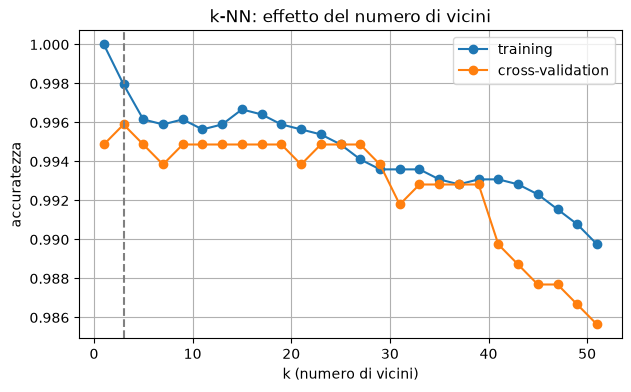

In [16]:
# 1. Provo diversi valori di k con la cross-validation
valori_k = range(1, 52, 2)
griglia_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": valori_k}, cv=cv,
                           scoring="accuracy", return_train_score=True)
griglia_knn.fit(X_train_scalato, y_train)
modello_knn = griglia_knn.best_estimator_
print("Miglior k:", griglia_knn.best_params_["n_neighbors"])
print("Accuratezza media in CV:", round(griglia_knn.best_score_, 4))

# 2. Confronto accuratezza sul training e in cross-validation al variare di k
plt.figure(figsize=(7, 4))
plt.plot(valori_k, griglia_knn.cv_results_["mean_train_score"], marker="o", label="training")
plt.plot(valori_k, griglia_knn.cv_results_["mean_test_score"], marker="o", label="cross-validation")
plt.axvline(griglia_knn.best_params_["n_neighbors"], color="gray", linestyle="--")
plt.xlabel("k (numero di vicini)")
plt.ylabel("accuratezza")
plt.title("k-NN: effetto del numero di vicini")
plt.legend()
plt.grid(True)
plt.show()

**Effetto della regolarizzazione**

Per k-NN la regolarizzazione è il numero di vicini k. Con k = 1 l'accuratezza sul training è 1.0, perché ogni punto è il vicino di sé stesso; aumentando k il modello fa la media su più vicini e il confine tra le classi diventa più liscio. La CV sceglie k = 3, con un'accuratezza del 99.6%, la più alta tra tutti i modelli. Per k grandi l'accuratezza scende lentamente (98.6% con k = 51), perché il modello inizia a considerare anche punti lontani.

Le curve però sono quasi piatte: l'accuratezza resta sopra il 98.5% per tutti i k. Questo conferma quello che avevo visto con t-SNE e DBSCAN: le banconote vicine tra loro appartengono quasi sempre alla stessa classe.

#### 3.6 Confronto dei modelli sul test set

,accuratezza,precisione,recall,F1-score
Regressione logistica,0.989,0.982,0.994,0.988
ID3,0.995,0.988,1.000,0.994
Naive Bayes,0.871,0.895,0.810,0.850
k-NN,1.000,1.000,1.000,1.000


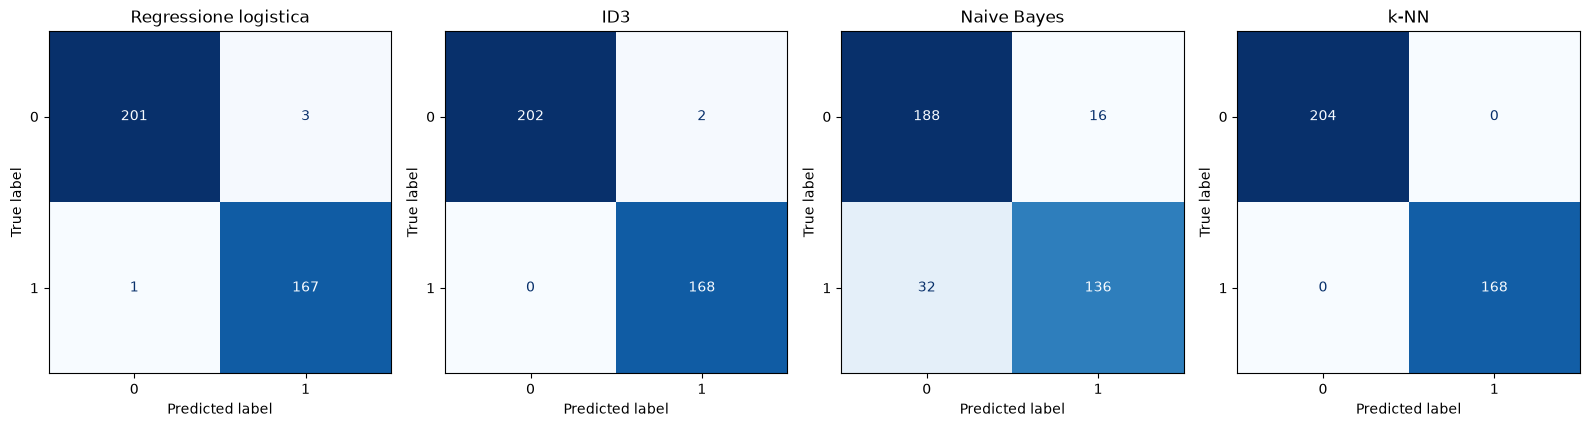

In [17]:
# 1. Calcolo le predizioni di ogni modello sul test set
predizioni = {
    "Regressione logistica": modello_log.predict(X_test_scalato),
    "ID3": modello_id3.predict(X_test_d),
    "Naive Bayes": modello_nb.predict(X_test),
    "k-NN": modello_knn.predict(X_test_scalato),
}

# 2. Calcolo le metriche per ogni modello
metriche = pd.DataFrame({nome: {"accuratezza": accuracy_score(y_test, y_pred),
                                "precisione": precision_score(y_test, y_pred),
                                "recall": recall_score(y_test, y_pred),
                                "F1-score": f1_score(y_test, y_pred)}
                         for nome, y_pred in predizioni.items()}).T
display(metriche.round(3))

# 3. Mostro la matrice di confusione di ogni modello
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (nome, y_pred) in zip(ax, predizioni.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=a, cmap="Blues", colorbar=False)
    a.set_title(nome)
plt.tight_layout()
plt.show()

**Confronto dei modelli sul test set**

k-NN classifica correttamente tutte le 372 banconote del test set. ID3 ne sbaglia 2 e la regressione logistica 4, quindi anche loro funzionano molto bene. Naive Bayes invece ne sbaglia 48 (accuratezza 87.1%) e soprattutto ne perde 32 di classe 1, per cui la recall scende all'81%.

I risultati sono coerenti con quelli della cross-validation, quindi i modelli non sono andati in overfitting. Il test set però è piccolo: tra k-NN, ID3 e la regressione logistica la differenza è di 2–4 banconote, quindi non posso dire con certezza quale sia davvero il migliore.

**Commento alla luce dell'analisi non supervisionata**

- **k-NN** è il migliore, come mi aspettavo da t-SNE e DBSCAN: le banconote vicine appartengono quasi sempre alla stessa classe, ed è proprio l'ipotesi su cui si basa k-NN.
- **La regressione logistica** funziona bene anche se nella proiezione PCA le classi non erano linearmente separabili: la separazione lineare esiste in 4 dimensioni, ma non si vede nelle prime due componenti.
- **Naive Bayes** va male perché le sue ipotesi non sono rispettate: le feature sono correlate e ogni classe è fatta di tanti gruppetti, non di una sola gaussiana.
- **K-means** non trovava le classi perché non formano due gruppi compatti, ma la struttura locale dei dati le distingue bene, e i metodi supervisionati la sfruttano.

**Come si potrebbero migliorare i risultati?**

- **Naive Bayes**: decorrelare prima le feature, per esempio con la PCA, oppure stimare le distribuzioni senza assumere che siano gaussiane.
- **Regressione logistica**: aggiungere feature polinomiali, così il confine tra le classi può essere curvo.
- **ID3**: scegliere le soglie dei bin in base all'information gain invece che con i quantili, oppure combinare tanti alberi (random forest).
- **Valutazione**: visto che il test set è piccolo, ripetere la divisione training/test con seed diversi e fare la media dei risultati.